# Final Customer Return-Risk Test

## tl;dr

This notebook applies the frozen Gradient Boosting pipeline and the previously selected 0.37 campaign cutoff to the sealed test period. No feature, model, hyperparameter, or cutoff is changed after seeing these results.

## Finalization contract

- Model: frozen from validation-stage selection
- Campaign cutoff: frozen at 0.37
- Test partition: opened by the evaluation function once
- Later reruns: display saved predictions and metrics without reselection
- Purpose: estimate performance in the latest historical period

In [1]:
from pathlib import Path
import json, os, sys
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.final_test_evaluation import evaluate_once
sns.set_theme(style='whitegrid')

## Results

### 1. Run or recover the immutable final evaluation

In [2]:
result = evaluate_once()
print(json.dumps(result, indent=2))
assert result['evaluated_once'] is True

{
  "model": "gradient_boosting",
  "campaign_threshold": 0.37000000000000016,
  "test_rows": 14341,
  "test_period_start": "2011-06-24T00:00:00",
  "test_period_end": "2011-08-23T00:00:00",
  "actual_return_rate": 0.3672686702461474,
  "metrics": {
    "accuracy": 0.7555958440833973,
    "precision": 0.6701429123213596,
    "recall": 0.6588190620846782,
    "f1": 0.6644327429392054,
    "roc_auc": 0.8062633359639968,
    "pr_auc": 0.7485088351625717
  },
  "confusion_matrix": {
    "true_negative": 7366,
    "false_positive": 1708,
    "false_negative": 1797,
    "true_positive": 3470
  },
  "validation_to_test_change": {
    "accuracy": 0.051540224152922254,
    "precision": 0.10671958068610743,
    "recall": -0.06595158011715663,
    "f1": 0.03044019493118022,
    "roc_auc": 0.021834290382849786,
    "pr_auc": 0.03388610021626326
  },
  "evaluated_once": true
}


### 2. Compare validation and final-test metrics

,Validation,Final test
accuracy,0.704,0.756
precision,0.563,0.670
recall,0.725,0.659
f1,0.634,0.664
roc_auc,0.784,0.806
pr_auc,0.715,0.749


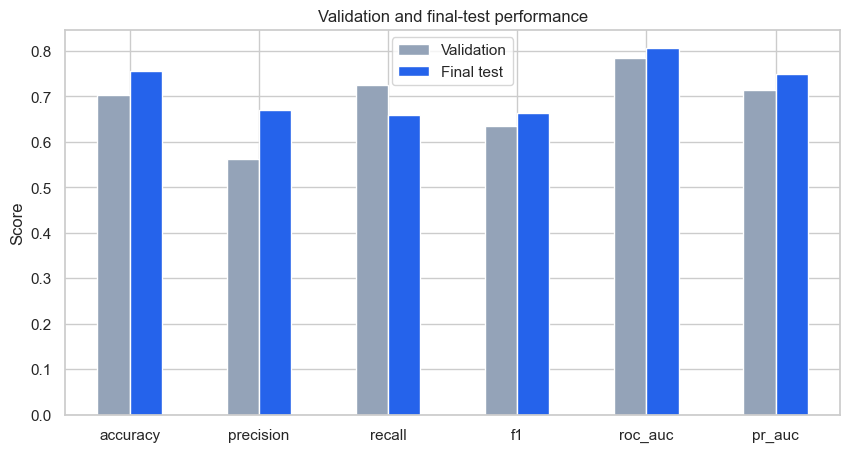

In [3]:
metadata = json.loads((ROOT / 'models/return_risk_metadata.json').read_text())
validation = pd.Series(metadata['validation_metrics'], name='Validation')
test = pd.Series(result['metrics'], name='Final test')
comparison = pd.concat([validation, test], axis=1)
display(comparison.style.format('{:.3f}'))
comparison.plot.bar(figsize=(10,5), color=['#94A3B8','#2563EB'])
plt.title('Validation and final-test performance'); plt.ylabel('Score'); plt.xticks(rotation=0); plt.show()

### 3. Review final confusion matrix

,Not selected,Selected for campaign
Actually did not return,7366,1708
Actually returned,1797,3470


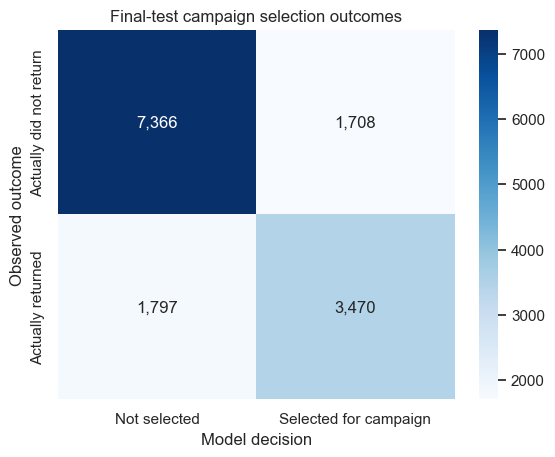

In [4]:
cm = result['confusion_matrix']
matrix = pd.DataFrame(
 [[cm['true_negative'],cm['false_positive']],[cm['false_negative'],cm['true_positive']]],
 index=['Actually did not return','Actually returned'],
 columns=['Not selected','Selected for campaign'])
display(matrix)
sns.heatmap(matrix, annot=True, fmt=',', cmap='Blues')
plt.title('Final-test campaign selection outcomes'); plt.xlabel('Model decision'); plt.ylabel('Observed outcome'); plt.show()

### 4. Check final-period calibration

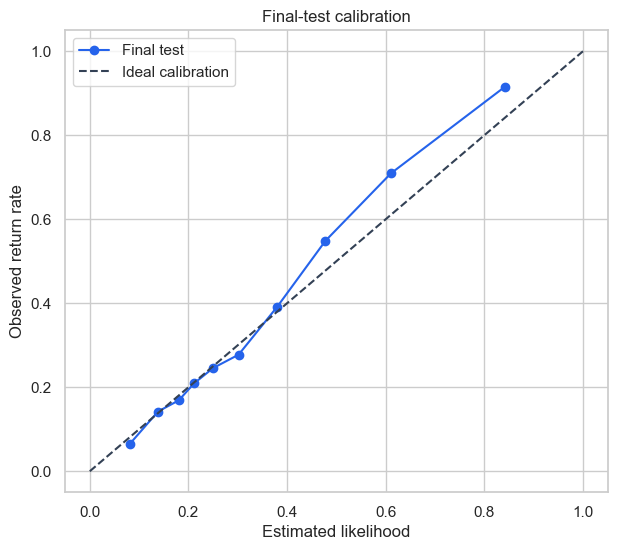

In [5]:
calibration = pd.read_csv(ROOT / 'reports/generated/classification_final_test_calibration.csv')
plt.figure(figsize=(7,6))
plt.plot(calibration['predicted_probability'], calibration['observed_return_rate'], marker='o', color='#2563EB', label='Final test')
plt.plot([0,1],[0,1], '--', color='#334155', label='Ideal calibration')
plt.title('Final-test calibration'); plt.xlabel('Estimated likelihood'); plt.ylabel('Observed return rate'); plt.legend(); plt.show()

### 5. Inspect performance by recency without changing the model

In [6]:
scored = pd.read_parquet(ROOT / 'reports/generated/classification_final_test_predictions.parquet')
scored['recency_band'] = pd.cut(scored['recency_days'], [-float('inf'),30,90,180,float('inf')], labels=['0–30 days','31–90 days','91–180 days','181+ days'])
segment = scored.groupby('recency_band', observed=True).agg(
 snapshots=('snapshot_id','size'), actual_return_rate=('returned_within_90_days','mean'),
 average_estimated_likelihood=('estimated_return_likelihood','mean'), campaign_selection_rate=('selected_for_campaign','mean'))
display(segment)

,snapshots,actual_return_rate,average_estimated_likelihood,campaign_selection_rate
recency_band,,,,
0–30 days,2412,0.722637,0.643965,0.851575
31–90 days,2565,0.601949,0.505718,0.766862
91–180 days,2344,0.354949,0.349763,0.400597
181+ days,7020,0.163533,0.186570,0.031054


## Interpretation rules

Test results are final evidence, not a new tuning signal. Any weakness found here becomes a limitation or future experiment; it does not authorize changing the current model and reporting a second test score.

## Takeaways

- The latest historical period is evaluated using a frozen model and cutoff.
- Validation-to-test changes reveal temporal generalization, not tuning opportunities.
- Confusion-matrix counts translate model performance into campaign-selection consequences.
- Calibration shows whether estimated likelihoods match observed rates.
- The source covers an old, single-retailer period, so external validity remains limited.